<a href="https://colab.research.google.com/github/Carlos-Biologist/Automated-_Detection_and_Tracking_Pinnipeds_UAVs_YOLO26_-_BoT-SORT/blob/main/Mallaria_Cell_COVID19_Radiography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Malaria Cell Image Dataset**

In [1]:
# https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria

import kagglehub # Acessar datasets do Kaggle
import os # Funções para interagir com o sistema operacional, como navegar em diretórios, criar pastas, ou manipular arquivos
from PIL import Image # Abrir, manipular, e salvar imagens em diversos formatos
import numpy as np # Biblioteca para operações matemáticas em arrays e matrizes multidimensionais
import matplotlib.pyplot as plt # Criar visualizações gráficas

In [2]:
# Download dataset
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
Path to dataset files: /kaggle/input/cell-images-for-detecting-malaria


### **Passo 1: Carregar as Imagens das Pastas**

In [3]:
parasitado = '/root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images/Parasitized'
nao_parasitado = '/root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images/Uninfected'

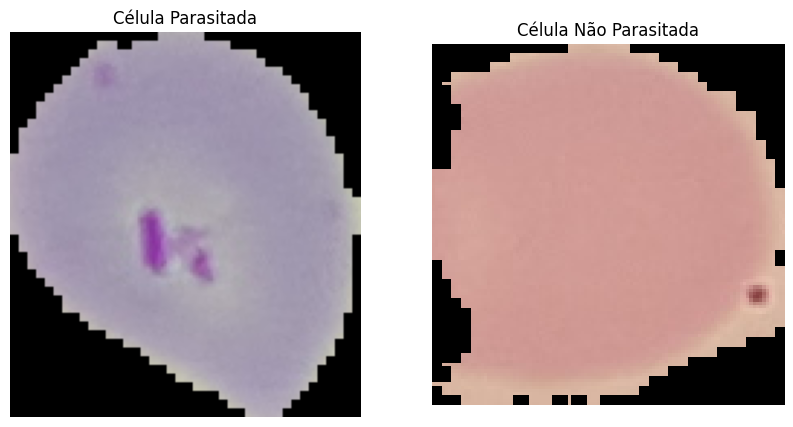

In [4]:
parasitado = os.path.join(path, 'cell_images', 'Parasitized')
nao_parasitado = os.path.join(path, 'cell_images', 'Uninfected')

# Selecionar uma imagem de cada pasta
img_parasitado = Image.open(os.path.join(parasitado, os.listdir(parasitado)[10]))
img_nao_parasitado = Image.open(os.path.join(nao_parasitado, os.listdir(nao_parasitado)[10]))

# Plotar as imagens
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_parasitado)
plt.title('Célula Parasitada')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_nao_parasitado)
plt.title('Célula Não Parasitada')
plt.axis('off')

plt.show()

In [5]:
# Lista para armazenar as imagens e os rótulos
images = []
labels = []

In [6]:
# Carregar imagens de células parasitadas
for filename in os.listdir(parasitado):
    file_path = os.path.join(parasitado, filename)
    if filename.endswith('.png'):  # Verifica se é uma imagem
        try:
            img = Image.open(file_path).convert('RGB')  # Converte para RGB
            img = img.resize((32, 32))  # Redimensiona a imagem para 32x32 (pode ajustar conforme necessário)
            images.append(np.array(img))
            labels.append(1)  # Rótulo 1 para parasitado
        except Exception as e:
            print(f'Erro ao carregar imagem {filename}: {e}')

In [7]:
# Carregar imagens de células não parasitadas
for filename in os.listdir(nao_parasitado):
    file_path = os.path.join(nao_parasitado, filename)
    if filename.endswith('.png'):  # Verifica se é uma imagem
        try:
            img = Image.open(file_path).convert('RGB')
            img = img.resize((32, 32))
            images.append(np.array(img))
            labels.append(0)  # Rótulo 0 para não parasitado
        except Exception as e:
            print(f'Erro ao carregar imagem {filename}: {e}')

In [8]:
# Converter para arrays NumPy
images = np.array(images)
labels = np.array(labels)

In [12]:
images.shape

(27558, 32, 32, 3)

In [13]:
labels.shape

(27558,)

### **Passo 2: Dividir em Conjuntos de Treino e Teste**

In [14]:
from sklearn.model_selection import train_test_split # Separar treino e teste
from tensorflow.keras.utils import to_categorical # transformar classes em categórico

In [20]:
# 1. Separar 70% (treino + validação) e 30% (teste)
X_temp, X_test, y_temp, y_test = train_test_split(
    images, labels, test_size=0.30, random_state=42, stratify=labels
)

# 2. Dividir os 70% restantes em 60% treino e 10% validação (10 / 70 = 1/7)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(1/7), random_state=42, stratify=y_temp
)

In [21]:
# Normalizar as imagens
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [22]:
# Converter rótulos para categóricos
y_train = to_categorical(y_train, num_classes=2)
y_val = to_categorical(y_val, num_classes=2)
y_test = to_categorical(y_test, num_classes=2)

### **Passo 3: Construir e Treinar a Rede Neural Artificial**

In [24]:
from tensorflow import keras
from tensorflow.keras import Sequential # Importa o modelo Sequential, usado para empilhar camadas de redes neurais de forma linear, onde a saída de uma camada é a entrada da próxima.
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout # Importa a camada Dense, que é uma camada totalmente conectada onde cada neurônio recebe entrada de todos os neurônios da camada anterior.
                                                            # Importa a camada Flatten, que transforma uma entrada multidimensional (ex.: imagem) em um vetor unidimensional, útil para conectar camadas convolucionais com camadas densas.
                                                            # Importa a camada Dropout, que desativa aleatoriamente uma fração de neurônios durante o treinamento para reduzir o overfitting.

In [25]:
# Criar o modelo (usando Input para evitar o UserWarning do Keras)
model = Sequential([
    Input(shape=X_train.shape[1:]),                  # Define explicitamente o formato de entrada
    Flatten(),                                       # Transformar entradas em um vetor unidimensional
    Dense(512, activation='relu'),                   # Camada oculta 1
    Dense(256, activation='relu'),                   # Camada oculta 2
    #Dense(128, activation='relu'),                  # Camada oculta 3
    #Dense(64, activation='relu'),                   # Camada oculta 4
    Dense(2, activation='sigmoid')                   # Camada de saída com 2 neurônios
])

In [28]:
# Compilar o modelo
model.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

In [29]:
# Treinar o modelo utilizando o conjunto de validação
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=156,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.6714 - loss: 0.6037 - val_accuracy: 0.6887 - val_loss: 0.5851
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6814 - loss: 0.5935 - val_accuracy: 0.6934 - val_loss: 0.5898
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6807 - loss: 0.5918 - val_accuracy: 0.6796 - val_loss: 0.6045
Epoch 4/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6862 - loss: 0.5886 - val_accuracy: 0.6851 - val_loss: 0.5863
Epoch 5/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6873 - loss: 0.5835 - val_accuracy: 0.6858 - val_loss: 0.5848
Epoch 6/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6900 - loss: 0.5808 - val_accuracy: 0.6941 - val_loss: 0.5785
Epoch 7/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6839 - loss: 0.5881 - val_accuracy: 0.6811 - val_loss: 0.5877
Epoch 8/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6923 - loss: 0.5789 - val_accuracy: 0

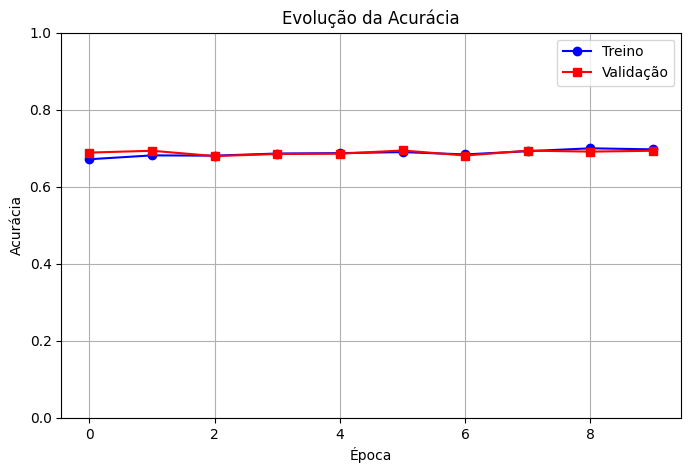

In [31]:
# Plotar acurácia de treino e validação
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Treino', color='blue', marker='o')
plt.plot(history.history['val_accuracy'], label='Validação', color='red', marker='s')

plt.title('Evolução da Acurácia')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.ylim(0, 1)  # eixo Y começa no 0 e vai até 1
plt.legend()
plt.grid(True)
plt.show()

In [30]:
# Avaliar o desempenho final no conjunto de teste (30% nunca vistos no treino)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia no conjunto de teste: {test_acc:.4f}")

Acurácia no conjunto de teste: 0.6837


In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [33]:
# Fazer predições no conjunto de teste
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Converter probabilidades para classes

# Converter rótulos de teste para o formato original (não-categórico)
y_test_classes = np.argmax(y_test, axis=1)

259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


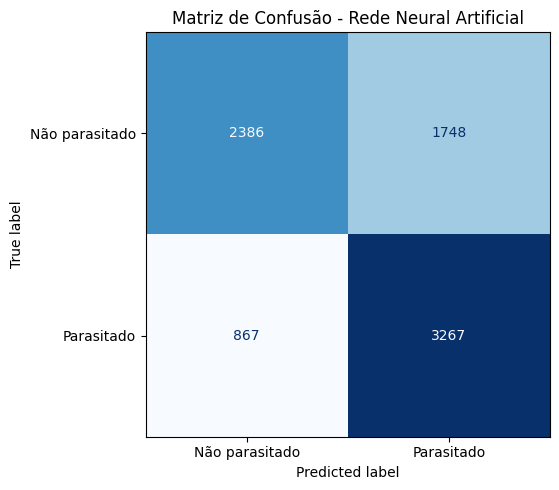

In [34]:
# Matriz de confusão para o modelo Rede Neural Artificial
cm_rna = confusion_matrix(y_test_classes, y_pred_classes)
disp_rna = ConfusionMatrixDisplay(confusion_matrix=cm_rna,
                                  display_labels=['Não parasitado', 'Parasitado'])

# Criar a figura
fig, ax = plt.subplots(figsize=(6, 5))
disp_rna.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de Confusão - Rede Neural Artificial')

plt.tight_layout()
plt.show()

### **Passo 4: Construir e Treinar a Rede Neural Convolucional**

In [35]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [36]:
# Construir a Rede Neural Convolucional
cnn_model = Sequential([
    # Primeira camada convolucional
    Conv2D(32, (3,3), activation='relu', input_shape=X_train.shape[1:]),
    MaxPooling2D(pool_size=(2,2)),

    # Segunda camada convolucional
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    # Terceira camada convolucional
    #Conv2D(128, (3,3), activation='relu'),
    #MaxPooling2D(pool_size=(2,2)),

    Flatten(),

    # Camadas densas
    Dense(128, activation='relu'),
    Dropout(0.5),  # Evitar overfitting
    Dense(64, activation='relu'),

    # Camada de saída
    Dense(2, activation='sigmoid')  # Softmax é melhor para classificação multiclasse
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
# Compilar o modelo
cnn_model.compile(optimizer='Adam',
                  loss='binary_crossentropy',  # para labels one-hot
                  metrics=['accuracy'])

In [38]:
# Treinar e validar o modelo
history_cnn = cnn_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=156,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - accuracy: 0.6595 - loss: 0.6219 - val_accuracy: 0.7402 - val_loss: 0.5183
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8063 - loss: 0.4361 - val_accuracy: 0.8501 - val_loss: 0.3472
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8859 - loss: 0.2878 - val_accuracy: 0.9158 - val_loss: 0.2139
Epoch 4/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9197 - loss: 0.2135 - val_accuracy: 0.9303 - val_loss: 0.1869
Epoch 5/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9392 - loss: 0.1729 - val_accuracy: 0.9485 - val_loss: 0.1521
Epoch 6/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9468 - loss: 0.1539 - val_accuracy: 0.9521 - val_loss: 0.1417
Epoch 7/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9513 - loss: 0.1431 - val_accuracy: 0.9496 - val_loss: 0.1325
Epoch 8/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9541 - loss: 0.1337 - val_accuracy:

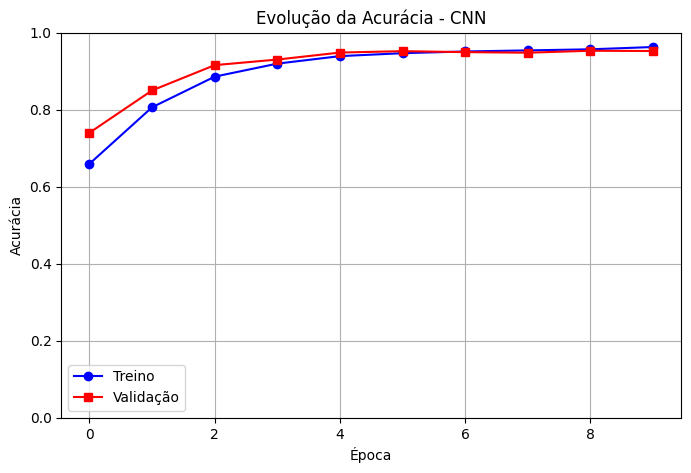

In [39]:
# Plotar acurácia de treino e validação da CNN
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['accuracy'], label='Treino', color='blue', marker='o')
plt.plot(history_cnn.history['val_accuracy'], label='Validação', color='red', marker='s')

plt.title('Evolução da Acurácia - CNN')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.ylim(0, 1)  # eixo Y começa no 0 e vai até 1
plt.legend()
plt.grid(True)
plt.show()

In [40]:
# Avaliar o desempenho final no conjunto de teste (30% nunca vistos)
test_loss_cnn, test_acc_cnn = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia da CNN no conjunto de teste: {test_acc_cnn:.4f}")

Acurácia da CNN no conjunto de teste: 0.9490


In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [43]:
# ===== CNN =====
y_pred_probs_cnn = cnn_model.predict(X_test)
y_pred_classes_cnn = np.argmax(y_pred_probs_cnn, axis=1)

cm_cnn = confusion_matrix(y_test_classes, y_pred_classes_cnn)
disp_cnn = ConfusionMatrixDisplay(confusion_matrix=cm_cnn,
                                  display_labels=['Não parasitado', 'Parasitado'])

259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


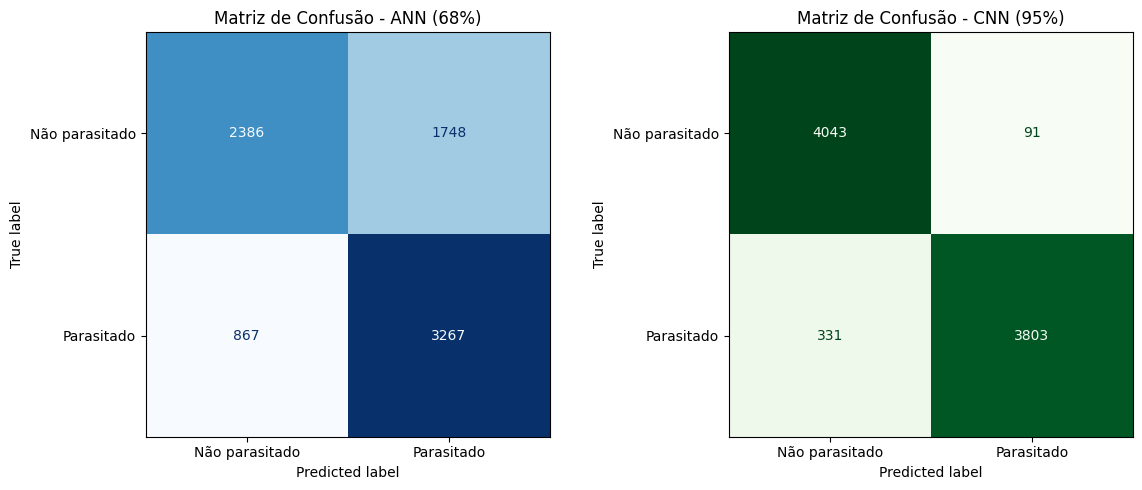

In [46]:
# ===== Plot lado a lado =====
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ANN
disp_rna.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de Confusão - ANN (68%)')

# CNN
disp_cnn.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Matriz de Confusão - CNN (95%)')

plt.tight_layout()
plt.show()

### **COVID-19 Radiography Database**

In [47]:
# ==========================================================
# 1. Baixar dados
# ==========================================================

import kagglehub
import os
from collections import defaultdict

# Download da versão mais recente
path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")
print("✅ Dataset baixado com sucesso!")
print("📁 Caminho local:", path)

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
✅ Dataset baixado com sucesso!
📁 Caminho local: /kaggle/input/covid19-radiography-database


In [48]:
# ==========================================================
# 2. Detectar o diretório base (onde estão as pastas das classes)
# ==========================================================

from collections import defaultdict

# Caminho base no ambiente Kaggle
base_dir = "/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset"

# Conferir estrutura principal
print("📂 Subpastas encontradas:", os.listdir(base_dir))

📂 Subpastas encontradas: ['Lung_Opacity.metadata.xlsx', 'Normal.metadata.xlsx', 'README.md.txt', 'COVID.metadata.xlsx', 'Normal', 'Lung_Opacity', 'Viral Pneumonia.metadata.xlsx', 'Viral Pneumonia', 'COVID']


In [49]:
# ==========================================================
# 3. Contar número de imagens
# ==========================================================

# Dicionário para contagem
image_counts = defaultdict(int)

# Percorrer classes e contar imagens na subpasta 'images'
for cls in os.listdir(base_dir):
    class_path = os.path.join(base_dir, cls, "images")
    if os.path.exists(class_path):
        count = len([f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        image_counts[cls] = count

# Mostrar resultados
print("\n📊 Contagem de imagens por classe:")
for cls, count in image_counts.items():
    print(f"   {cls:<20} → {count} imagens")


📊 Contagem de imagens por classe:
   Normal               → 10192 imagens
   Lung_Opacity         → 6012 imagens
   Viral Pneumonia      → 1345 imagens
   COVID                → 3616 imagens


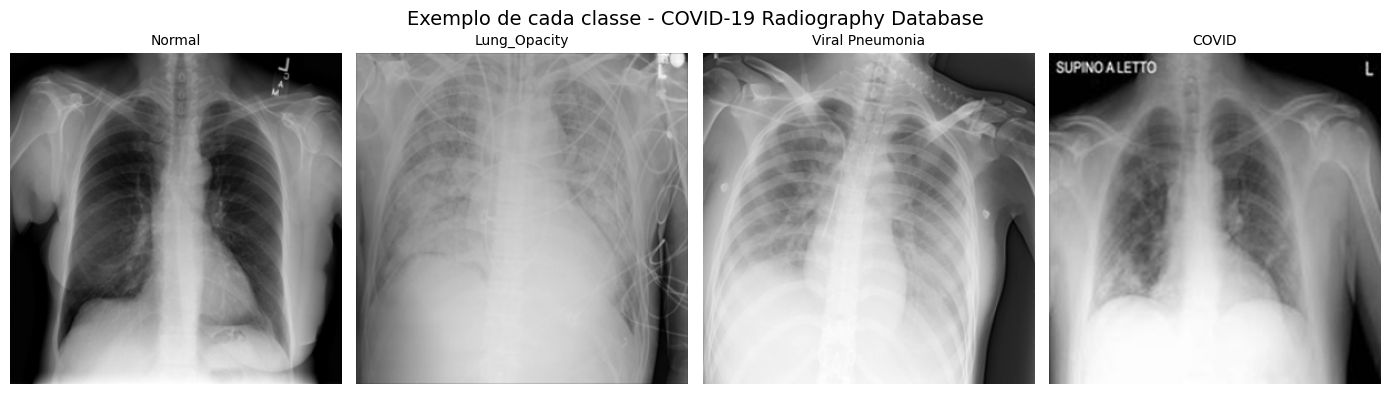

In [50]:
# ==========================================================
# 4. Plotar uma imagem de cada classes
# ==========================================================

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os

# Caminho base no ambiente Kaggle
base_dir = "/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset"

# Classes
classes = ["Normal", "Lung_Opacity", "Viral Pneumonia", "COVID"]

# Criar figura
fig, axs = plt.subplots(1, 4, figsize=(14, 4))

for i, cls in enumerate(classes):
    img_dir = os.path.join(base_dir, cls, "images")
    img_file = random.choice(os.listdir(img_dir))
    img_path = os.path.join(img_dir, img_file)

    img = mpimg.imread(img_path)
    axs[i].imshow(img, cmap="gray")
    axs[i].set_title(cls, fontsize=10)
    axs[i].axis("off")

plt.suptitle("Exemplo de cada classe - COVID-19 Radiography Database", fontsize=14)
plt.tight_layout()
plt.show()